In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import dataclasses
import pickle
import os

Mounted at /content/drive


In [ ]:

import sys, os

GIT_USER  = "JoeyTurn"
GIT_REPO  = "kernels_can_icl"

!git clone https://github.com/{GIT_USER}/{GIT_REPO}.git
!git clone https://github.com/dkarkada/expt-core.git

sys.path.insert(0, "/content/kernels_can_icl")
sys.path.insert(0, "/content/expt-core")

DATASETPATH = "/content/drive/MyDrive/datasets"
RESULTPATH  = "/content/drive/MyDrive/results"
os.environ["DATASETPATH"] = DATASETPATH
os.environ["RESULTPATH"]  = RESULTPATH
os.makedirs(DATASETPATH, exist_ok=True)
os.makedirs(RESULTPATH,  exist_ok=True)

Cloning into 'kernel_ICL'...
remote: Enumerating objects: 798, done.
remote: Counting objects: 100% (333/333), done.
remote: Compressing objects: 100% (232/232), done.
remote: Total 798 (delta 198), reused 231 (delta 96), pack-reused 465 (from 1)
Receiving objects: 100% (798/798), 55.73 MiB | 19.16 MiB/s, done.
Resolving deltas: 100% (392/392), done.
Cloning into 'modelscape'...
remote: Enumerating objects: 234, done.
remote: Counting objects: 100% (234/234), done.
remote: Compressing objects: 100% (156/156), done.
remote: Total 234 (delta 142), reused 168 (delta 76), pack-reused 0 (from 0)
Receiving objects: 100% (234/234), 218.78 KiB | 11.51 MiB/s, done.
Resolving deltas: 100% (142/142), done.
Cloning into 'expt-core'...
remote: Enumerating objects: 58, done.
remote: Counting objects: 100% (58/58), done.
remote: Compressing objects: 100% (41/41), done.
remote: Total 58 (delta 28), reused 47 (delta 17), pack-reused 0 (from 0)
Receiving objects: 100% (58/58), 16.11 KiB | 16.11 MiB/s, d

In [ ]:
from misc import rcsetup
rcsetup()

In [ ]:
%matplotlib inline
# os/pickle are also imported by the Drive cell above; repeated here so this notebook still runs
# if the Colab cells are skipped (e.g. plotting from a local copy of the pickles).
import os
import glob
import pickle

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

## 1. Find the pickles

Run this first. It prints every `overlap_*.pkl` in the folder with its `T`, `L`, `d`, kernel and
overlap shape, which is how you fill in `FILES` below.

**Check the `T` column shows four different values.** The configs carried
`base_name = 'HEA_validation_T10'`, which does not track `T` &mdash; if that survived into the
overlap runs, every save went to the same filename and clobbered the previous one. Identical rows
here mean the runs need redoing with a `T`-dependent `base_name`.

In [ ]:
FOLDER = "/content/drive/My Drive/picl/results/kernels/eigenstructure/"


def list_overlap_pickles(folder, pattern="overlap_*.pkl"):
    """Print every overlap pickle in `folder` with its config, so the real filenames (and any
    collision between runs) are visible before anything is plotted."""
    paths = sorted(glob.glob(os.path.join(folder, pattern)))
    if not paths:
        print(f"no files matching {pattern} in {folder}")
        return []
    print(f"{'file':<46} {'T':>5} {'L':>3} {'d':>3} {'kernel':>16} "
          f"{'overlap':>10} {'N_MODES':>8} {'NBINS':>6}")
    for p in paths:
        try:
            with open(p, "rb") as f:
                d = pickle.load(f)
        except Exception as exc:                                # pragma: no cover
            print(f"{os.path.basename(p):<46} <unreadable: {exc}>")
            continue
        c, r = d.get("config", {}), d.get("results", {})
        ov = r.get("overlap")
        shape = "-" if ov is None else "x".join(str(s) for s in np.shape(ov))
        print(f"{os.path.basename(p):<46} {str(c.get('T')):>5} {str(c.get('L')):>3} "
              f"{str(c.get('dim')):>3} {str(c.get('kernel_class')):>16} {shape:>10} "
              f"{str(d.get('N_MODES')):>8} {str(d.get('NBINS')):>6}")
    return paths


_ = list_overlap_pickles(FOLDER)

file                                               T   L   d           kernel    overlap  N_MODES  NBINS
overlap_HEA_validation_T16_gaussian_eigspace.pkl    16   7   4   GaussianKernel      15x15    25600     20
overlap_HEA_validation_T1_polynomial_eigspace.pkl     1   7   4 PolynomialKernel      14x14    25600     20
overlap_HEA_validation_T256_laplace_eigspace.pkl   256  10   4    LaplaceKernel      12x12    25600     20
overlap_HEA_validation_T4_reluntk_eigspace.pkl     4   7   4          ReluNTK      17x17    25600     20


## 2. Load

Fill `FILES` in with the real names from the listing above. Order here is the column order in the
figure.

In [ ]:
FILES = {
    "T=1, Inner-Product Kernel":   "overlap_HEA_validation_T1_polynomial_eigspace.pkl",      # <-- paste the real filenames
    "T=4, ReLU NTK":   "overlap_HEA_validation_T4_reluntk_eigspace.pkl",
    "T=16, Gaussian Kernel":  "overlap_HEA_validation_T16_gaussian_eigspace.pkl",
    "T=256, Laplace Kernel": "overlap_HEA_validation_T256_laplace_eigspace.pkl",
}


def _to_numpy(x):
    """emp_eigs is a torch tensor (possibly on cuda); th_eigs is already numpy."""
    if hasattr(x, "detach"):
        x = x.detach().cpu()
    return np.asarray(x, dtype=float)


def load_overlap(folder, files):
    """files: {panel label -> filename}.  Returns {label -> loaded dict}, insertion-ordered."""
    data = {}
    for label, name in files.items():
        path = os.path.join(folder, name)
        with open(path, "rb") as f:
            d = pickle.load(f)
        r = d.get("results", {})
        if "overlap" not in r:
            raise KeyError(f"{name}: no 'overlap' key -- this looks like an old-format pickle "
                           f"(keys: {sorted(r)})")
        if "bin_edges" not in r:
            raise KeyError(f"{name}: no 'bin_edges' key; cannot label the heatmap axes")
        M = np.asarray(r["overlap"], dtype=float)
        edges = np.asarray(r["bin_edges"], dtype=float)
        if M.ndim != 2 or M.shape[0] != M.shape[1]:
            raise ValueError(f"{name}: overlap must be square, got {M.shape}")
        if M.shape[0] != len(edges) - 1:
            raise ValueError(
                f"{name}: overlap is {M.shape[0]}x{M.shape[0]} but bin_edges has "
                f"{len(edges) - 1} bins. These must match -- the usual cause is saving a "
                f"compact_bins() result alongside the uncompacted edges; save the raw "
                f"eigenspace_overlap output instead.")
        data[label] = d
    return data


data = load_overlap(FOLDER, FILES)
print("loaded:", ", ".join(f"{k} ({data[k]['results']['overlap'].shape[0]} bins)"
                           for k in data))

loaded: T=1, Inner-Product Kernel (14 bins), T=4, ReLU NTK (17 bins), T=16, Gaussian Kernel (15 bins), T=256, Laplace Kernel (12 bins)


In [ ]:
def load_eigs(folder, files, overlap_data=None):
    """Eigenvalue-only pickles, for when the spectra live somewhere other than the overlap files.

    Only `emp_eigs` / `th_eigs` are required, so the older
    `{config, results:{emp_eigs, th_eigs}}` format works unchanged.  Pass `overlap_data` to
    cross-check each column is really the same run.
    """
    out = {}
    for label, name in files.items():
        with open(os.path.join(folder, name), "rb") as f:
            d = pickle.load(f)
        r = d.get("results", {})
        for key in ("emp_eigs", "th_eigs"):
            if key not in r:
                raise KeyError(f"{name}: missing '{key}' (keys present: {sorted(r)})")
        if overlap_data is not None and label in overlap_data:
            a, b = d.get("config", {}), overlap_data[label].get("config", {})
            differing = [k for k in ("T", "L", "dim", "kernel_class")
                         if k in a and k in b and a[k] != b[k]]
            if differing:
                print(f"WARNING {label}: eigenvalue pickle {name} disagrees with the overlap "
                      f"pickle on {differing} -- "
                      + ", ".join(f"{k}: {a[k]} vs {b[k]}" for k in differing))
            if "n" in a and "n" in b and a["n"] != b["n"]:
                print(f"note {label}: eigenvalues computed at n={a['n']}, overlap at n={b['n']}; "
                      f"each is normalised by its own n")
        out[label] = d
    return out

EIG_FILES = {
    "T=1, Inner-Product Kernel":   "innerproductkernel_T1_L7_d4.pkl",
    "T=4, ReLU NTK":   "reluntkernel_T4_L7_d4.pkl",
    "T=16, Gaussian Kernel":  "gaussiankernel_T16_L7_d4.pkl",
    "T=256, Laplace Kernel": "laplacekernel_T256_L10_d4.pkl",
}
EIG_FOLDER = FOLDER          # or a different directory
eig = load_eigs(EIG_FOLDER, EIG_FILES, overlap_data=data)

# eig = None                     # None -> top row comes from the overlap pickles

## 3. Panel helpers

`prepare` is the function from `picl_eigenstructure_validation_plot.ipynb`, with one change: the
theory scale comes from the saved `pp` (the Gaussian kernel prefactor) instead of the hand-entered
`th_scale` constants &mdash; those numbers (`0.7879…`, `0.7750…`, …) *were* `pp`.

In [ ]:
# Font sizes, in points on the AUTHORED figure. The figure is ~14.3 in wide and goes into LaTeX
# at \textwidth (5.5 in), i.e. everything is scaled by 0.385 -- so a 6 pt tick prints at 2.3 pt.
FS = {
    "suptitle": 19, "title": 16, "label": 14, "tick": 12,
    "heat_tick": 11, "legend": 12, "cbar_label": 13, "cbar_tick": 12,
}


def prepare(loaded, n=None, th_scale=None):
    r = loaded["results"]
    emp = np.sort(_to_numpy(r["emp_eigs"]).ravel())[::-1]
    th = np.sort(_to_numpy(r["th_eigs"]).ravel())[::-1]
    if n is None:
        n = loaded["config"]["n"]
    if th_scale is None:
        th_scale = float(r["pp"]) if "pp" in r else 1.0
    return emp / float(n), th * th_scale


def draw_eigenvalues(ax, emp, th, lam_lo, lam_hi, show_legend=False):
    keep = max(int((emp >= lam_lo).sum()), int((th >= lam_lo).sum()), 2)
    keep = min(keep, len(emp), len(th))
    idx = np.arange(1, keep + 1)
    ax.loglog(idx, np.clip(emp[:keep], 1e-300, None), lw=1.7, color="#1f77b4", label="Empirical")
    ax.loglog(idx, np.clip(th[:keep], 1e-300, None), lw=1.7, color="black", ls="--",
              label="Theoretical")
    ax.set_xlim(1, max(keep, 2))
    ax.set_ylim(lam_lo, lam_hi)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=FS["tick"])
    if show_legend:
        ax.legend(frameon=False, loc="lower left", fontsize=FS["legend"])
    return keep


def draw_overlap(ax, overlap, bin_edges, max_ticks=3, show_ticks=True):
    M = np.asarray(overlap, dtype=float)
    edges = np.asarray(bin_edges, dtype=float)
    D = M[::-1, ::-1]
    centers = np.sqrt(edges[:-1] * edges[1:])[::-1]
    cmap = mpl.colormaps.get_cmap("magma").copy()
    cmap.set_bad(color="#333333")
    im = ax.imshow(np.ma.masked_invalid(D), cmap=cmap, vmin=0.0, vmax=1.0,
                   origin="upper", interpolation="nearest", aspect="equal")
    nb = D.shape[0]
    if not show_ticks:
        ax.set_xticks([]); ax.set_yticks([])
        return im
    step = max(1, int(np.ceil(nb / max_ticks)))
    ticks = np.arange(0, nb, step)
    ax.set_xticks(ticks); ax.set_yticks(ticks)
    ax.set_xticklabels([f"{centers[i]:.0e}" for i in ticks], fontsize=FS["heat_tick"])
    ax.set_yticklabels([f"{centers[i]:.0e}" for i in ticks], fontsize=FS["heat_tick"])
    ax.xaxis.set_ticks_position("bottom")
    ax.tick_params(length=2)
    return im

## 4. The figure

In [ ]:
# def plot_fig2(data, suptitle=None, per_column_range=False, panel=(3.4, 3.3), outpath=None):
#     """2 x len(data) figure: eigenvalues on top, eigenspace overlap below, one column per run."""
#     labels = list(data)
#     ncol = len(labels)
#     edges_by = {lab: np.asarray(data[lab]["results"]["bin_edges"], float) for lab in labels}
#     lam_lo = min(e[0] for e in edges_by.values())
#     lam_hi = max(e[-1] for e in edges_by.values())

#     fig, axes = plt.subplots(2, ncol, figsize=(panel[0] * ncol, panel[1] * 2),
#                              constrained_layout=True, squeeze=False)
#     im = None
#     for j, lab in enumerate(labels):
#         d = data[lab]
#         edges = edges_by[lab]
#         lo, hi = (edges[0], edges[-1]) if per_column_range else (lam_lo, lam_hi)
#         emp, th = prepare(d)
#         draw_eigenvalues(axes[0, j], emp, th, lo, hi, show_legend=(j == 0))
#         axes[0, j].set_title(lab, fontsize=12)
#         axes[0, j].set_xlabel("Index")
#         im = draw_overlap(axes[1, j], d["results"]["overlap"], edges)
#         axes[1, j].set_xlabel("Empirical eigenspace", fontsize=9)
#         if j == 0:
#             axes[0, j].set_ylabel("Eigenvalue")
#             axes[1, j].set_ylabel("Predicted eigenspace", fontsize=9)
#         else:
#             axes[0, j].tick_params(labelleft=False)

#     cb = fig.colorbar(im, ax=axes[1, :].tolist(), fraction=0.025, pad=0.01)
#     cb.set_label("eigenspace overlap", fontsize=9)
#     cb.ax.set_yticks([0.0, 0.5, 1.0])
#     if suptitle:
#         fig.suptitle(suptitle, fontsize=14)
#     if outpath:
#         fig.savefig(outpath, bbox_inches="tight")
#     return fig, axes
def plot_fig2(data, eig_data=None, th_scale=None, suptitle=None, per_column_range=False,
              panel=(3.57, 3.66), outpath=None, heat_ticks=True):
    """2 x len(data) figure: eigenvalues on top, eigenspace overlap below, one column per run.

    eig_data:  optional {label -> eigenvalue pickle} for the TOP row.  Defaults to `data`.
    th_scale:  optional theory-scale override, a float or {label -> float}.  Only needed when the
               eigenvalue pickles predate the saved `pp`.
    panel:     per-panel inches.  (3.57, 3.66) matches the HEA paper's Fig 2.
    """
    labels = list(data)
    ncol = len(labels)
    edges_by = {lab: np.asarray(data[lab]["results"]["bin_edges"], float) for lab in labels}
    lam_lo = min(e[0] for e in edges_by.values())
    lam_hi = max(e[-1] for e in edges_by.values())

    fig, axes = plt.subplots(2, ncol, figsize=(panel[0] * ncol, panel[1] * 2),
                             constrained_layout=True, squeeze=False)
    im = None
    for j, lab in enumerate(labels):
        d = data[lab]
        edges = edges_by[lab]
        lo, hi = (edges[0], edges[-1]) if per_column_range else (lam_lo, lam_hi)
        src = (eig_data or data)[lab]
        # Theory scale: explicit override > the source's own pp > the overlap pickle's pp.
        if th_scale is not None:
            ts = th_scale[lab] if isinstance(th_scale, dict) else float(th_scale)
        elif "pp" in src["results"]:
            ts = None                                   # prepare() reads it from the source
        elif "pp" in d["results"]:
            ts = float(d["results"]["pp"])
        else:
            ts = None
        emp, th = prepare(src, th_scale=ts)
        draw_eigenvalues(axes[0, j], emp, th, lo, hi, show_legend=(j == 0))
        # axes[0, j].set_title(lab, fontsize=12)
        # axes[0, j].set_xlabel("Index")
        # im = draw_overlap(axes[1, j], d["results"]["overlap"], edges)
        # axes[1, j].set_xlabel("Empirical eigenspace", fontsize=9)
        # if j == 0:
        #     axes[0, j].set_ylabel("Eigenvalue")
        #     axes[1, j].set_ylabel("Predicted eigenspace", fontsize=9)
        # else:
        #     axes[0, j].tick_params(labelleft=False)

        axes[0, j].set_title(lab, fontsize=FS["title"])
        axes[0, j].set_xlabel("Index", fontsize=FS["label"])
        im = draw_overlap(axes[1, j], d["results"]["overlap"], edges, show_ticks=heat_ticks)
        axes[1, j].set_xlabel("Empirical eigenspace", fontsize=FS["label"])
        if j == 0:
            axes[0, j].set_ylabel("Eigenvalue", fontsize=FS["label"])
            axes[1, j].set_ylabel("Predicted eigenspace", fontsize=FS["label"])




    cb = fig.colorbar(im, ax=axes[1, :].tolist(), fraction=0.025, pad=0.01)
    cb.set_label("eigenspace\noverlap", fontsize=FS["cbar_label"])
    cb.ax.set_yticks([0.0, 0.5, 1.0])
    cb.ax.tick_params(labelsize=FS["cbar_tick"])
    if suptitle:
        fig.suptitle(suptitle, fontsize=FS["suptitle"])
    # cb.set_label("eigenspace overlap", fontsize=9)
    # cb.ax.set_yticks([0.0, 0.5, 1.0])
    # if suptitle:
    #     fig.suptitle(suptitle, fontsize=14)
    if outpath:
        fig.savefig(outpath, bbox_inches="tight")
    return fig, axes

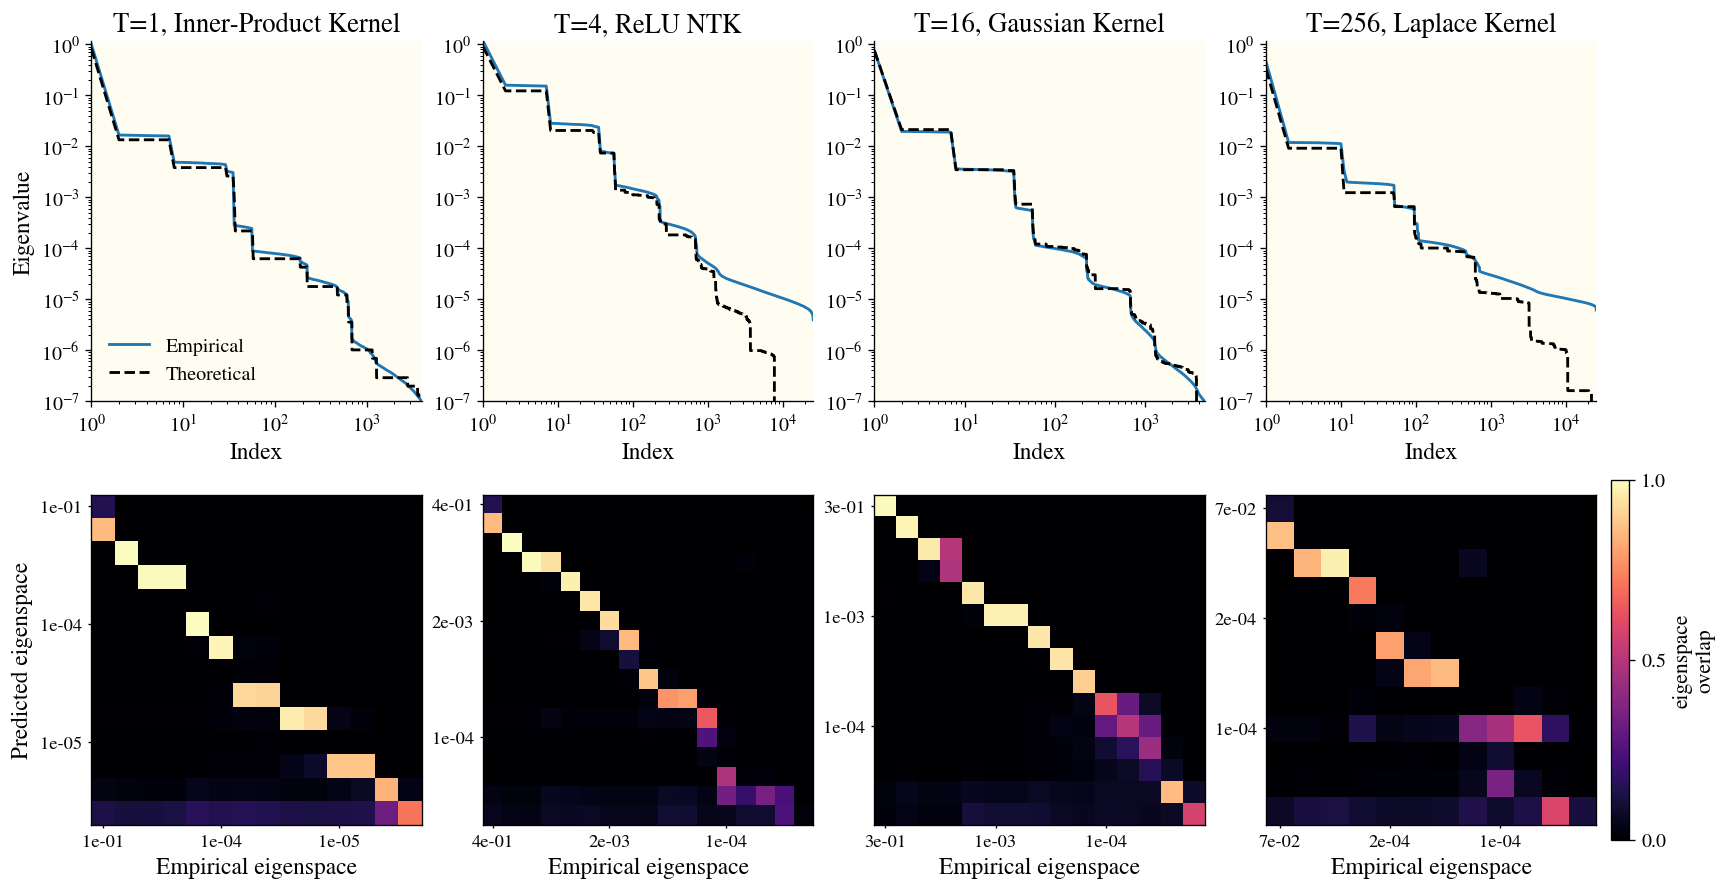

saved -> /content/drive/My Drive/picl/results/kernels/eigenstructure/eigenstructure_fig2_new.pdf


In [ ]:
fig, axes = plot_fig2(
    data,
    eig_data=eig,                # <-- add
    # suptitle="Gaussian Kernel eigenstructure (L=7, d=4)",
    per_column_range=False,
    panel=(3.57, 3.66),          # <-- add (paper's Fig 2 panel size)
    outpath=os.path.join(FOLDER, "eigenstructure_fig2_new.pdf"),
)
plt.show()
print("saved ->", os.path.join(FOLDER, "eigenstructure_fig2_new.pdf"))